# Guía 6 — Parte IV: Síntesis — la onda plana y los invariantes de Lorentz

**Electromagnetismo Intermedio · Universidad de Valparaíso · 2026**

**Problema 15** y una síntesis de toda la guía. La onda plana

$$\mathbf{E}=E_0\cos(kz-\omega t)\,\hat{x},\qquad \mathbf{B}=\frac{E_0}{c}\cos(kz-\omega t)\,\hat{y},\qquad\omega=ck,$$

es el prototipo de campo **nulo**: $F_{\mu\nu}F^{\mu\nu}=0$ y $\mathbf{E}\cdot\mathbf{B}=0$. Todo campo de radiación de la Parte I es localmente así.

Contenido:

1. Visualización 3D y animación de la onda.
2. Maxwell en el vacío con SymPy: por qué hace falta $\omega=ck$.
3. Invariantes, Poynting y promedio temporal.
4. Boosts: efecto Doppler (boost paralelo) y aberración (boost transversal). La onda **sigue siendo nula** en todo sistema.
5. El tensor de energía-momento $T^{\mu\nu}\propto k^\mu k^\nu$.
6. **Síntesis**: el plano de invariantes. Los campos de los Problemas 6, 7 y 15 bajo cientos de boosts aleatorios.

Unidades: $c=1$, $\varepsilon_0=\mu_0=1$ (salvo en SymPy, donde dejamos $c$ explícito).

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import Image, display

import sys, os
sys.path.insert(0, os.path.abspath('..'))   # em_utils.py está en la raíz del repositorio
import em_utils as u
u.estilo()
C = u.COLORES
np.set_printoptions(precision=5, suppress=True)

---
## 1. La onda en 3D

[guardado] figuras/P15_onda_plana_3D.png


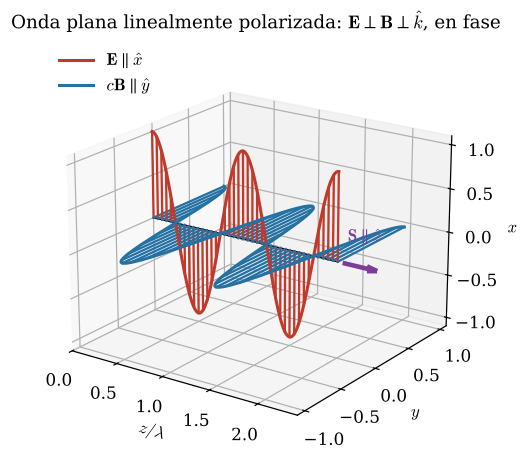

[guardado] figuras/P15_animacion_onda_plana.gif  (0.45 MB)


In [2]:
E0, k = 1.0, 2*np.pi        # lambda = 1
w = k                       # c = 1
zs = np.linspace(0, 2, 41)

def dibujar(A, t):
    A.cla()
    f = np.cos(k*zs - w*t)
    A.plot(zs, 0*zs, 0*zs, color='k', lw=1)
    for zi, fi in zip(zs, f):
        A.plot([zi, zi], [0, 0], [0, E0*fi], color=C['E'], lw=1.5)        # E en x (eje vertical del dibujo)
        A.plot([zi, zi], [0, E0*fi], [0, 0], color=C['B'], lw=1.5)        # cB en y
    zz = np.linspace(0, 2, 300); ff = np.cos(k*zz - w*t)
    A.plot(zz, 0*zz, E0*ff, color=C['E'], lw=2, label=r'$\mathbf{E}\parallel\hat{x}$')
    A.plot(zz, E0*ff, 0*zz, color=C['B'], lw=2, label=r'$c\mathbf{B}\parallel\hat{y}$')
    A.quiver(2.05, 0, 0, 0.35, 0, 0, color=C['S'], lw=3, arrow_length_ratio=0.3)
    A.text(2.1, 0, 0.25, r'$\mathbf{S}\parallel\hat{z}$', color=C['S'])
    A.set_xlabel('$z/\\lambda$'); A.set_ylabel('$y$'); A.set_zlabel('$x$')
    A.set_xlim(0, 2.4); A.set_ylim(-1.1, 1.1); A.set_zlim(-1.1, 1.1)
    A.view_init(elev=20, azim=-55); A.legend(loc='upper left')

fig = plt.figure(figsize=(9, 5))
A = fig.add_subplot(projection='3d'); dibujar(A, 0.0)
A.set_title('Onda plana linealmente polarizada: $\\mathbf{E}\\perp\\mathbf{B}\\perp\\hat{k}$, en fase')
u.guardar(fig, 'P15_onda_plana_3D'); plt.show()

fig = plt.figure(figsize=(7.5, 4.5)); A = fig.add_subplot(projection='3d')
fr = 30
anim = animation.FuncAnimation(fig, lambda i: dibujar(A, i/fr), frames=fr)
u.guardar_gif(anim, 'P15_animacion_onda_plana', fps=15, dpi=70)
plt.close(fig)
# la animación se muestra en la celda siguiente (figuras/P15_animacion_onda_plana.gif)

![animación](figuras/P15_animacion_onda_plana.gif)

---
## 2. Las cuatro ecuaciones de Maxwell en el vacío (inciso a)

Dejamos $\omega$ y $k$ **independientes** y calculamos los residuos. Gauss y $\nabla\cdot\mathbf{B}=0$ se cumplen siempre, porque la onda es transversal. Faraday y Ampère–Maxwell solo se cumplen si $\omega=ck$: la relación de dispersión es una *condición*, no un dato.

In [3]:
t, x, y, z = sp.symbols('t x y z', real=True)
c, E0s, ks, ws = sp.symbols('c E_0 k omega', positive=True)
fase = ks*z - ws*t
Ev = sp.Matrix([E0s*sp.cos(fase), 0, 0])
Bv = sp.Matrix([0, E0s/c*sp.cos(fase), 0])
div = lambda V: sp.diff(V[0], x) + sp.diff(V[1], y) + sp.diff(V[2], z)
curl = lambda V: sp.Matrix([sp.diff(V[2], y) - sp.diff(V[1], z), sp.diff(V[0], z) - sp.diff(V[2], x), sp.diff(V[1], x) - sp.diff(V[0], y)])
print("∇·E                      =", sp.simplify(div(Ev)))
print("∇·B                      =", sp.simplify(div(Bv)))
far = sp.simplify(curl(Ev) + sp.diff(Bv, t))
amp = sp.simplify(curl(Bv) - sp.diff(Ev, t)/c**2)
print("∇×E + ∂B/∂t              =", sp.factor(far.T))
print("∇×B - (1/c²)∂E/∂t        =", sp.factor(amp.T))
print("con ω = ck:", sp.simplify(far.subs(ws, c*ks)).T, sp.simplify(amp.subs(ws, c*ks)).T)

∇·E                      = 0
∇·B                      = 0


∇×E + ∂B/∂t              = Matrix([[0, E_0*(-c*k + omega)*sin(k*z - omega*t)/c, 0]])
∇×B - (1/c²)∂E/∂t        = Matrix([[E_0*(c*k - omega)*sin(k*z - omega*t)/c**2, 0, 0]])
con ω = ck: Matrix([[0, 0, 0]]) Matrix([[0, 0, 0]])


---
## 3. Invariantes y vector de Poynting (incisos b y c)

max |F_μν F^μν| sobre la malla (z,t) = 0.0
max |E·B|                         = 0.0
[guardado] figuras/P15_poynting_promedio.png


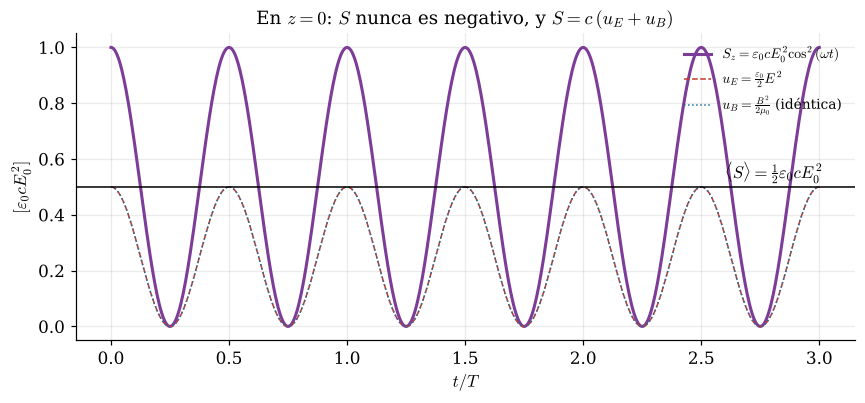

promedio numérico de S_z en un período: 0.5  (exacto: 1/2)


In [4]:
zz = np.linspace(0, 1, 7); tt = np.linspace(0, 1, 9)
ZZ, TT = np.meshgrid(zz, tt)
f = np.cos(k*ZZ - w*TT)
Eg = np.stack([E0*f, 0*f, 0*f], -1); Bg = np.stack([0*f, E0*f, 0*f], -1)
Fd = u.F_abajo(Eg, Bg)
print("max |F_μν F^μν| sobre la malla (z,t) =", np.abs(u.FF(Fd)).max())
print("max |E·B|                         =", np.abs(np.sum(Eg*Bg, -1)).max())

tl = np.linspace(0, 3, 600)
S = E0*np.cos(-w*tl)*E0*np.cos(-w*tl)            # S_z = E_x B_y / mu0  en z=0
uE = 0.5*(E0*np.cos(w*tl))**2; uB = 0.5*(E0*np.cos(w*tl))**2
fig, A = plt.subplots(figsize=(8, 3.8))
A.plot(tl, S, color=C['S'], lw=2, label=r'$S_z=\varepsilon_0cE_0^2\cos^2(\omega t)$')
A.plot(tl, uE, color=C['E'], lw=1, ls='--', label=r'$u_E=\frac{\varepsilon_0}{2}E^2$')
A.plot(tl, uB, color=C['B'], lw=1, ls=':', label=r'$u_B=\frac{B^2}{2\mu_0}$ (idéntica)')
A.axhline(0.5, color='k', lw=1); A.text(2.6, 0.53, r'$\langle S\rangle=\frac{1}{2}\varepsilon_0cE_0^2$')
A.set_xlabel(r'$t/T$'); A.set_ylabel(r'$[\varepsilon_0 c E_0^2]$'); A.legend(loc='upper right', fontsize=9)
A.set_title(r'En $z=0$: $S$ nunca es negativo, y $S=c\,(u_E+u_B)$')
fig.tight_layout(); u.guardar(fig, 'P15_poynting_promedio'); plt.show()
t1 = np.linspace(0, 1, 2000, endpoint=False)
print("promedio numérico de S_z en un período:", np.mean(np.cos(w*t1)**2), " (exacto: 1/2)")

---
## 4. La onda vista desde otros sistemas inerciales

**Boost paralelo a $\hat{k}$** ($\boldsymbol\beta=\beta\hat{z}$). Las amplitudes y la frecuencia se multiplican por el mismo factor Doppler,

$$\frac{E'}{E}=\frac{\omega'}{\omega}=\sqrt{\frac{1-\beta}{1+\beta}} .$$

Las dos cosas salen de transformar objetos distintos: $F^{\mu\nu}$ (amplitud) y $k^\mu$ (frecuencia).

**Boost transversal** ($\boldsymbol\beta=\beta\hat{x}$). La dirección de propagación cambia (**aberración**). Comprobamos que $\mathbf{S}'=\mathbf{E}'\times\mathbf{B}'$ apunta a lo largo de $\mathbf{k}'$, la parte espacial de $k'^\mu=\Lambda^\mu{}_\nu k^\nu$, y que la onda sigue siendo nula: $|\mathbf{E}'|=c|\mathbf{B}'|$ y $\mathbf{E}'\perp\mathbf{B}'$.

¿E'/E = ω'/ω = √((1-β)/(1+β))? True True
máx |ángulo(S') - ángulo(k')| = 4.263256414560601e-14 grados
máx |invariantes| tras boosts transversales = 8.881784197001252e-16


[guardado] figuras/P15_doppler_y_aberracion.png


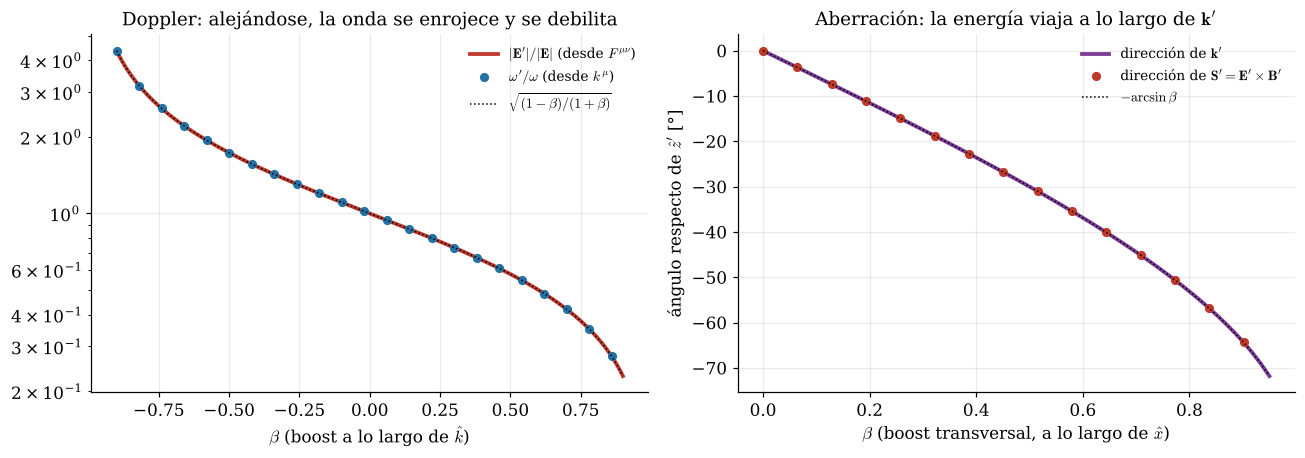

In [5]:
kmu = np.array([w, 0, 0, k])           # k^mu = (ω/c, 0, 0, k)
E_ev, B_ev = np.array([E0, 0, 0]), np.array([0, E0, 0])     # campos en el evento x^mu = 0 (fase = 0)

bs = np.linspace(-0.9, 0.9, 181)
amp, frec = [], []
for b in bs:
    Ep, Bp = u.boost_campos(E_ev, B_ev, [0, 0, b])
    kp = u.matriz_boost([0, 0, b]) @ kmu
    amp.append(np.linalg.norm(Ep)); frec.append(kp[0]/kmu[0])
amp, frec = np.array(amp), np.array(frec)
dop = np.sqrt((1 - bs)/(1 + bs))
print("¿E'/E = ω'/ω = √((1-β)/(1+β))?", np.allclose(amp, dop), np.allclose(frec, dop))

bx = np.linspace(0, 0.95, 60)
ang_S, ang_k, nulidad = [], [], []
for b in bx:
    Ep, Bp = u.boost_campos(E_ev, B_ev, [b, 0, 0])
    kp = u.matriz_boost([b, 0, 0]) @ kmu
    Sp = np.cross(Ep, Bp)
    ang_S.append(np.degrees(np.arctan2(Sp[0], Sp[2]))); ang_k.append(np.degrees(np.arctan2(kp[1], kp[3])))
    I1, I2 = u.invariantes(Ep, Bp); nulidad.append(max(abs(I1), abs(I2)))
print("máx |ángulo(S') - ángulo(k')| =", np.max(np.abs(np.array(ang_S) - np.array(ang_k))), "grados")
print("máx |invariantes| tras boosts transversales =", max(nulidad))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
A = ax[0]
A.plot(bs, amp, color=C['E'], lw=2.5, label=r"$|\mathbf{E}'|/|\mathbf{E}|$ (desde $F^{\mu\nu}$)")
A.plot(bs[::8], frec[::8], 'o', color=C['B'], ms=5, label=r"$\omega'/\omega$ (desde $k^\mu$)")
A.plot(bs, dop, 'k:', lw=1, label=r'$\sqrt{(1-\beta)/(1+\beta)}$')
A.set_yscale('log'); A.set_xlabel(r'$\beta$ (boost a lo largo de $\hat{k}$)'); A.legend(fontsize=9)
A.set_title('Doppler: alejándose, la onda se enrojece y se debilita')
A = ax[1]
A.plot(bx, ang_k, color=C['S'], lw=2.5, label=r"dirección de $\mathbf{k}'$")
A.plot(bx[::4], np.array(ang_S)[::4], 'o', color=C['E'], ms=5, label=r"dirección de $\mathbf{S}'=\mathbf{E}'\times\mathbf{B}'$")
A.plot(bx, -np.degrees(np.arcsin(bx)), 'k:', lw=1, label=r"$-\arcsin\beta$")
A.set_xlabel(r'$\beta$ (boost transversal, a lo largo de $\hat{x}$)'); A.set_ylabel('ángulo respecto de $\\hat{z}\'$ [°]')
A.set_title('Aberración: la energía viaja a lo largo de $\\mathbf{k}\'$'); A.legend(fontsize=9)
fig.tight_layout(); u.guardar(fig, 'P15_doppler_y_aberracion'); plt.show()

---
## 5. Tensor de energía-momento: $T^{\mu\nu}\propto k^\mu k^\nu$ (inciso d)

$$T^{\mu\nu}=\frac1{\mu_0}\Big[F^{\mu\alpha}\eta_{\alpha\beta}F^{\beta\nu}+\tfrac14\eta^{\mu\nu}F_{\alpha\beta}F^{\alpha\beta}\Big],\qquad T^{00}=u,\quad T^{0i}=S_i/c .$$

Para la onda plana se cumple $T^{\mu\nu}=\frac{\varepsilon_0E_0^2\cos^2\psi}{(\omega/c)^2}k^\mu k^\nu$. Lo comprobamos numéricamente, junto con $T^{\mu\nu}k_\nu=0$ y la traza nula $T^\mu{}_\mu=0$, la firma de un campo sin masa. Como contraste, el campo cruzado del Problema 6 **no** tiene esa forma.

In [6]:
def T_tensor(E, B):
    Fd = u.F_abajo(E, B); Fu = u.subir(Fd)
    return Fu @ u.ETA @ Fu + 0.25*np.linalg.inv(u.ETA)*u.FF(Fd)

for psi in [0.0, 0.7, 2.0]:
    Ec, Bc = E0*np.cos(psi)*np.array([1, 0, 0]), E0*np.cos(psi)*np.array([0, 1, 0])
    T = T_tensor(Ec, Bc)
    T_kk = E0**2*np.cos(psi)**2/kmu[0]**2*np.outer(kmu, kmu)
    k_dn = u.ETA @ kmu
    print(f"ψ={psi}: |T - (ε0E0²cos²ψ/k0²) k k| = {np.abs(T - T_kk).max():.1e},  "
          f"|T k| = {np.abs(T @ k_dn).max():.1e},  traza = {np.trace(u.ETA @ T):.1e}")
print("\nT^{μν} para ψ = 0:\n", T_tensor(np.array([E0, 0, 0]), np.array([0, E0, 0])))
print("\nCampo cruzado del Problema 6 (E0=1, B0=0.6):\n", T_tensor(np.array([1.0, 0, 0]), np.array([0, 0, 0.6])))
print("  -> no es de rango 1 (no es k k): rango =", np.linalg.matrix_rank(T_tensor(np.array([1.0, 0, 0]), np.array([0, 0, 0.6]))))

ψ=0.0: |T - (ε0E0²cos²ψ/k0²) k k| = 0.0e+00,  |T k| = 0.0e+00,  traza = 0.0e+00
ψ=0.7: |T - (ε0E0²cos²ψ/k0²) k k| = 1.3e-17,  |T k| = 0.0e+00,  traza = 0.0e+00
ψ=2.0: |T - (ε0E0²cos²ψ/k0²) k k| = 1.7e-18,  |T k| = 0.0e+00,  traza = 0.0e+00

T^{μν} para ψ = 0:
 [[1. 0. 0. 1.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [1. 0. 0. 1.]]

Campo cruzado del Problema 6 (E0=1, B0=0.6):
 [[ 0.68  0.   -0.6   0.  ]
 [ 0.   -0.32  0.    0.  ]
 [-0.6   0.    0.68  0.  ]
 [ 0.    0.    0.    0.32]]
  -> no es de rango 1 (no es k k): rango = 4


---
## 6. Síntesis: el plano de invariantes

Un campo electromagnético en un punto tiene seis componentes, pero solo **dos números invariantes**: $\mathcal I_1=E^2-c^2B^2$ e $\mathcal I_2=c\,\mathbf{E}\cdot\mathbf{B}$. Tomamos los campos que aparecieron en la guía y les aplicamos 400 boosts aleatorios (dirección uniforme, $|\boldsymbol\beta|<0.95$):

| Campo | De dónde viene | $\mathcal I_1$ | $\mathcal I_2$ |
|---|---|---|---|
| $\mathbf{E}=E_0\hat{y}$ | Problema 7 | $>0$ | 0 |
| $E_0\hat{x},\;0.6E_0/c\,\hat{z}$ | Problema 6 ($E>cB$) | $>0$ | 0 |
| $0.6E_0\hat{x},\;E_0/c\,\hat{z}$ | Problema 6 ($E<cB$) | $<0$ | 0 |
| onda plana | Problema 15 | 0 | 0 |
| $\mathbf{E}\parallel\mathbf{B}$ | contraejemplo | $\neq0$ | $\neq0$ |

**Izquierda:** en el plano $(c|\mathbf{B}|,|\mathbf{E}|)$, cada familia se desparrama a lo largo de una hipérbola $|\mathbf{E}|^2-c^2|\mathbf{B}|^2=\text{cte}$; la onda plana, sobre la diagonal $|\mathbf{E}|=c|\mathbf{B}|$. **Derecha:** en el plano de invariantes, cada familia colapsa a **un punto**.

P7: E puro                    I1 = +1.0000 ± 8.0e-16   I2 = -0.0000 ± 7.8e-17   |E| entre 1.00 y 3.15
P6: cruzado, E>cB             I1 = +0.6400 ± 1.1e-15   I2 = +0.0000 ± 1.4e-16   |E| entre 0.80 y 4.55
P6: cruzado, E<cB             I1 = -0.6400 ± 9.9e-16   I2 = +0.0000 ± 1.2e-16   |E| entre 0.07 y 4.52
P15: onda plana (nula)        I1 = -0.0000 ± 1.3e-15   I2 = +0.0000 ± 1.4e-16   |E| entre 0.23 y 5.78
E ∥ B                         I1 = +0.3900 ± 5.9e-16   I2 = +0.4000 ± 2.6e-16   |E| entre 0.80 y 2.93


[guardado] figuras/Sintesis_plano_de_invariantes.png


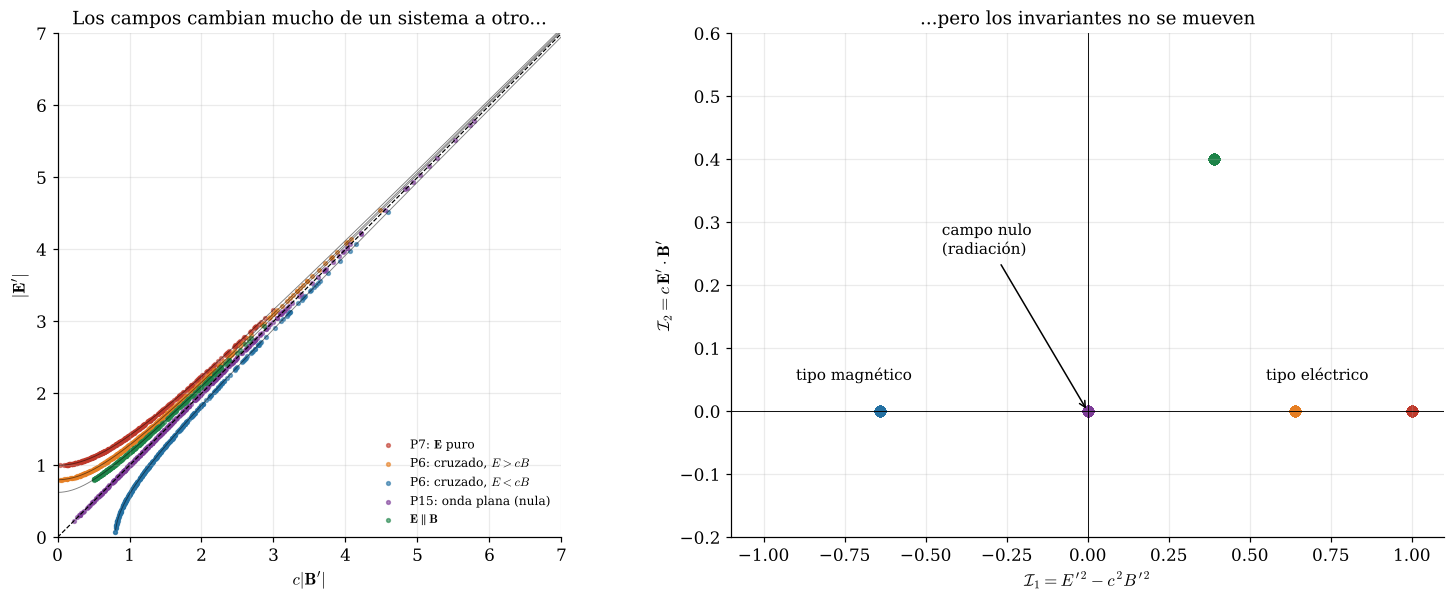

In [7]:
rng = np.random.default_rng(42)
def boosts_aleatorios(N=400, bmax=0.95):
    d = rng.normal(size=(N, 3)); d /= np.linalg.norm(d, axis=1, keepdims=True)
    return d*(bmax*rng.uniform(0, 1, N)**(1/3))[:, None]

familias = {
    'P7: $\\mathbf{E}$ puro':              (np.array([0, 1.0, 0]), np.array([0, 0, 0.0]), C['E']),
    'P6: cruzado, $E>cB$':                 (np.array([1.0, 0, 0]), np.array([0, 0, 0.6]), '#e67e22'),
    'P6: cruzado, $E<cB$':                 (np.array([0.6, 0, 0]), np.array([0, 0, 1.0]), C['B']),
    'P15: onda plana (nula)':              (np.array([1.0, 0, 0]), np.array([0, 1.0, 0]), C['S']),
    '$\\mathbf{E}\\parallel\\mathbf{B}$':  (np.array([0, 0, 0.8]), np.array([0, 0, 0.5]), C['v']),
}
B_rand = boosts_aleatorios()
fig, ax = plt.subplots(1, 2, figsize=(14, 5.6))
for nombre, (E, B, col) in familias.items():
    Es, Bs = zip(*[u.boost_campos(E, B, b) for b in B_rand])
    Es, Bs = np.array(Es), np.array(Bs)
    I1, I2 = u.invariantes(Es, Bs)
    ax[0].scatter(np.linalg.norm(Bs, axis=1), np.linalg.norm(Es, axis=1), s=6, color=col, alpha=0.6, label=nombre)
    ax[1].scatter(I1, I2, s=40, color=col, alpha=0.6, label=nombre)
    plano = nombre.replace('$\\mathbf{E}\\parallel\\mathbf{B}$', 'E ∥ B').replace('$\\mathbf{E}$', 'E').replace('$', '')
    print(f"{plano:28s}  I1 = {I1.mean():+.4f} ± {I1.std():.1e}   I2 = {I2.mean():+.4f} ± {I2.std():.1e}   "
          f"|E| entre {np.linalg.norm(Es, axis=1).min():.2f} y {np.linalg.norm(Es, axis=1).max():.2f}")
cb = np.linspace(0, 7, 400)
for I1 in [1.0, 0.64, 0.39, -0.64]:
    e2 = cb**2 + I1
    ax[0].plot(cb[e2 >= 0], np.sqrt(e2[e2 >= 0]), 'k-', lw=0.6, alpha=0.5)
ax[0].plot(cb, cb, 'k--', lw=0.8)
ax[0].set_xlim(0, 7); ax[0].set_ylim(0, 7); ax[0].set_aspect('equal')
ax[0].set_xlabel(r"$c|\mathbf{B}'|$"); ax[0].set_ylabel(r"$|\mathbf{E}'|$")
ax[0].set_title('Los campos cambian mucho de un sistema a otro...'); ax[0].legend(fontsize=8, loc='lower right')
ax[1].axhline(0, color='k', lw=0.6); ax[1].axvline(0, color='k', lw=0.6)
ax[1].set_xlabel(r"$\mathcal{I}_1=E'^2-c^2B'^2$"); ax[1].set_ylabel(r"$\mathcal{I}_2=c\,\mathbf{E}'\cdot\mathbf{B}'$")
ax[1].set_title('...pero los invariantes no se mueven')
ax[1].text(0.55, 0.05, 'tipo eléctrico', fontsize=10); ax[1].text(-0.9, 0.05, 'tipo magnético', fontsize=10)
ax[1].annotate('campo nulo\n(radiación)', (0, 0), (-0.45, 0.25), arrowprops=dict(arrowstyle='->'), fontsize=10)
ax[1].set_xlim(-1.1, 1.1); ax[1].set_ylim(-0.2, 0.6)
fig.tight_layout(); u.guardar(fig, 'Sintesis_plano_de_invariantes'); plt.show()

### Lo que dice esta última figura sobre toda la guía

- **Problema 7**: un campo puramente eléctrico ($\mathcal I_1>0$, $\mathcal I_2=0$) adquiere $\mathbf{B}'$ en otros sistemas, pero nunca puede volverse puramente magnético.
- **Problemas 6 y 8**: para campos cruzados, el signo de $\mathcal I_1$ decide si existe el sistema de deriva ($E<cB$, órbitas acotadas) o si la partícula se fuga ($E>cB$).
- **Problemas 1–4 y 15**: los campos de radiación son nulos ($\mathcal I_1=\mathcal I_2=0$). No hay sistema donde la luz esté "en reposo" ni donde sea puramente eléctrica: un boost solo cambia su color (Doppler) y su dirección (aberración). Su $T^{\mu\nu}\propto k^\mu k^\nu$ es el de un flujo de partículas sin masa, $p^\mu=\hbar k^\mu$.
- **Problemas 9–14**: toda esta estructura sale de una acción invariante, $-\frac1{4\mu_0}F_{\mu\nu}F^{\mu\nu}$, que es exactamente $\frac{1}{2\mu_0c^2}\mathcal I_1$. La invariancia de gauge de esa acción obliga a que la carga se conserve.